# Object Detection with a Pretrained Model

In this demo, we apply a pretrained object detector from torchvision, Faster R-CNN, to a few images. For each detected object, it returns a bounding box, a label and a score. We will:

1. load the model and apply it to the images, then display its boxes and scores;
2. compute the intersection over union (IoU) between two boxes, and compare the detections with a ground truth;
3. apply non-maximum suppression (NMS) ourselves, which the model usually does internally.

This demo needs no GPU: on a CPU, it runs in a few minutes.

## Images

PyTorch and torchvision are preinstalled on Colab and in the Codespace. The images are those of the examples in torchvision's documentation ([pytorch/vision](https://github.com/pytorch/vision/tree/v0.24.0/gallery/assets) repository, version 0.24.0):

- pedestrians, from the [Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/) database, with their annotated mask, which will be our ground truth;
- a skateboarder, a dog and a piece of pottery.

The next cell downloads them into the `images` folder, then reads them as integer tensors of shape `(channels, height, width)`.

In [1]:
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision.models.detection import (
  FasterRCNN_ResNet50_FPN_V2_Weights,
  fasterrcnn_resnet50_fpn_v2,
)
from torchvision.ops import batched_nms, box_iou, masks_to_boxes, nms
from torchvision.transforms.v2.functional import pil_to_tensor

base_url = "https://raw.githubusercontent.com/pytorch/vision/v0.24.0/gallery/assets"
names = ["FudanPed00054.png", "person1.jpg", "dog1.jpg", "pottery.jpg"]
mask_name = "FudanPed00054_mask.png"

image_dir = Path("images")
image_dir.mkdir(exist_ok=True)
for name in [*names, mask_name]:
  if not (image_dir / name).exists():
    urllib.request.urlretrieve(f"{base_url}/{name}", image_dir / name)

images = [pil_to_tensor(Image.open(image_dir / name).convert("RGB")) for name in names]
for name, image in zip(names, images):
  print(f"{name}: {tuple(image.shape)}, {image.dtype}")

FudanPed00054.png: (3, 498, 533), torch.uint8
person1.jpg: (3, 640, 480), torch.uint8
dog1.jpg: (3, 500, 500), torch.uint8
pottery.jpg: (3, 1200, 900), torch.uint8


## The Model

Faster R-CNN is a **two-stage** detector:

- a backbone (here ResNet-50 with an FPN, Feature Pyramid Network) computes feature maps at several scales;
- first stage: the RPN (Region Proposal Network) proposes candidate regions, likely to contain an object;
- second stage: the ROI head (Region of Interest) gives the class of each region and refines its box.

The `DEFAULT` weights come from a training on [COCO](https://cocodataset.org/), a dataset of 80 classes of common objects. `weights.transforms()` converts an image to floats in $[0, 1]$: the model resizes and normalizes it itself. `weights.meta["categories"]` gives the name of each class (91 indices: the `__background__`, the 80 classes, and `N/A` for the numbers COCO planned without annotating them).

The first load downloads the weights (167 MB).

In [2]:
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT  # pretrained on COCO
model = fasterrcnn_resnet50_fpn_v2(weights=weights).eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]

n_params = sum(parameter.numel() for parameter in model.parameters())
n_classes = len([name for name in categories if name not in ("__background__", "N/A")])
print(f"{n_params / 1e6:.0f} million parameters, {n_classes} classes")
print(f"First stage: {type(model.rpn).__name__}")
print(f"Second stage: {type(model.roi_heads).__name__}")
print(f"mAP on COCO val2017: {weights.meta['_metrics']['COCO-val2017']['box_map']}")

44 million parameters, 80 classes
First stage: RegionProposalNetwork
Second stage: RoIHeads
mAP on COCO val2017: 46.7


## Inference

The model takes a list of images, of any size, and returns one dictionary per image:

- `boxes`: the boxes, of shape `(N, 4)`, in the `x1 y1 x2 y2` format (top left and bottom right corners, in pixels of the original image);
- `labels`: the class index of each box;
- `scores`: the model's confidence, in decreasing order.

It returns at most 100 detections per image, with a score above 0.05.

In [3]:
with torch.no_grad():
  outputs = model([preprocess(image) for image in images])

for name, output in zip(names, outputs):
  print(f"{name}: {len(output['boxes'])} detections")
  for box, label, score in zip(
    output["boxes"][:5], output["labels"][:5], output["scores"][:5]
  ):
    print(f"  {categories[label]:<14} {score:.3f}  {[round(x) for x in box.tolist()]}")

FudanPed00054.png: 37 detections
  person         1.000  [363, 115, 438, 332]
  person         1.000  [287, 113, 362, 334]
  person         0.999  [95, 133, 184, 422]
  person         0.998  [490, 120, 519, 196]
  sports ball    0.957  [33, 163, 47, 178]
person1.jpg: 9 detections
  person         0.999  [125, 178, 322, 569]
  skateboard     0.998  [159, 549, 343, 584]
  baseball bat   0.853  [10, 310, 308, 478]
  baseball bat   0.215  [106, 223, 442, 415]
  bowl           0.179  [244, 345, 270, 363]
dog1.jpg: 4 detections
  dog            0.998  [219, 171, 407, 389]
  person         0.412  [344, 163, 359, 224]
  person         0.249  [300, 167, 316, 233]
  person         0.098  [302, 200, 313, 233]
pottery.jpg: 4 detections
  fire hydrant   0.770  [103, 208, 802, 980]
  teddy bear     0.552  [116, 224, 799, 961]
  elephant       0.209  [112, 242, 797, 970]
  vase           0.060  [102, 233, 806, 967]


## Displaying the Boxes

Low-score detections are often wrong: before displaying, we only keep those whose score is above a threshold, here 0.5. Each box is labeled with its class and its score.

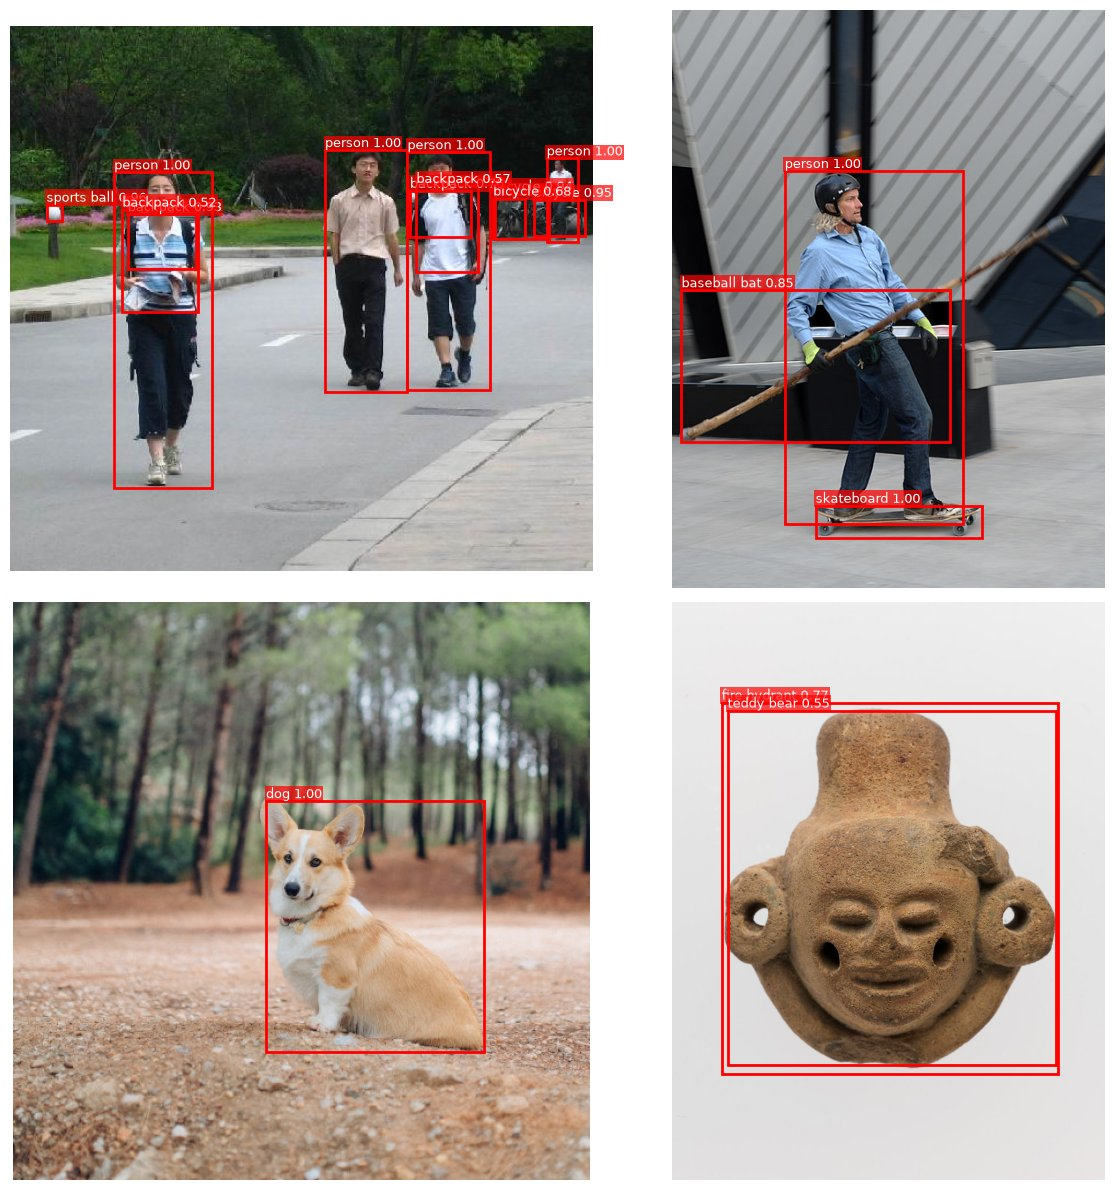

In [4]:
score_threshold = 0.5


def show_image(ax, image):
  ax.imshow(image.permute(1, 2, 0))  # (height, width, channels) for matplotlib
  ax.axis("off")


def draw_boxes(ax, boxes, texts=None, color="red", linewidth=2):
  """Draw the x1 y1 x2 y2 boxes, each with its text above it."""
  for i, (x1, y1, x2, y2) in enumerate(boxes.tolist()):
    ax.add_patch(
      Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=linewidth
      )
    )
    if texts is not None:
      ax.text(
        x1,
        y1,
        texts[i],
        color="white",
        fontsize=9,
        va="bottom",
        bbox={"facecolor": color, "alpha": 0.7, "pad": 1, "edgecolor": "none"},
      )


def detection_texts(output, keep):
  return [
    f"{categories[label]} {score:.2f}"
    for label, score in zip(output["labels"][keep], output["scores"][keep])
  ]


fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, image, output in zip(axes.flat, images, outputs):
  keep = output["scores"] >= score_threshold
  show_image(ax, image)
  draw_boxes(ax, output["boxes"][keep], detection_texts(output, keep))
plt.tight_layout()
plt.show()

- The pedestrians, their backpacks, the bicycles in the background, the skateboarder, his board and the dog are well located and well classified.
- The white globe of the lamp post, left of the pedestrians, becomes a sports ball, with a score of 0.96: a high score doesn't guarantee a right detection.
- The skateboarder's stick becomes a baseball bat, and the pottery a fire hydrant or a teddy bear: the detector only knows COCO's 80 classes and always answers with one of them. For other classes, it is fine-tuned on one's own images by replacing its head (`FastRCNNPredictor`), or one takes an open-vocabulary detector (Grounding DINO, OWLv2, YOLO-World), which receives its classes as text.

The score threshold sets the trade-off between precision and recall: low, it keeps barely visible objects but also false detections, like the "persons" with a score of 0.41 and 0.25 that the model sees in the trees behind the dog; high, it loses real objects.

In [5]:
for threshold in (0.05, 0.3, 0.5, 0.9):
  counts = [int((output["scores"] >= threshold).sum()) for output in outputs]
  print(f"Score >= {threshold}: {dict(zip(names, counts))}")

Score >= 0.05: {'FudanPed00054.png': 37, 'person1.jpg': 9, 'dog1.jpg': 4, 'pottery.jpg': 4}
Score >= 0.3: {'FudanPed00054.png': 17, 'person1.jpg': 3, 'dog1.jpg': 2, 'pottery.jpg': 2}
Score >= 0.5: {'FudanPed00054.png': 12, 'person1.jpg': 3, 'dog1.jpg': 1, 'pottery.jpg': 2}
Score >= 0.9: {'FudanPed00054.png': 8, 'person1.jpg': 2, 'dog1.jpg': 1, 'pottery.jpg': 0}


## Intersection over Union (IoU)

IoU measures the overlap between two boxes:

$$\text{IoU} = \frac{\text{intersection area}}{\text{union area}} \in [0, 1]$$

A detection is considered correct if its IoU with a ground truth box is above a threshold, often 0.5.

For the pedestrians image, the Penn-Fudan database provides a mask: each pixel is 0 on the background, and $i$ on the $i$-th annotated pedestrian. `masks_to_boxes` derives each pedestrian's bounding box from it: that's our ground truth.

3 annotated pedestrians, 4 detected persons


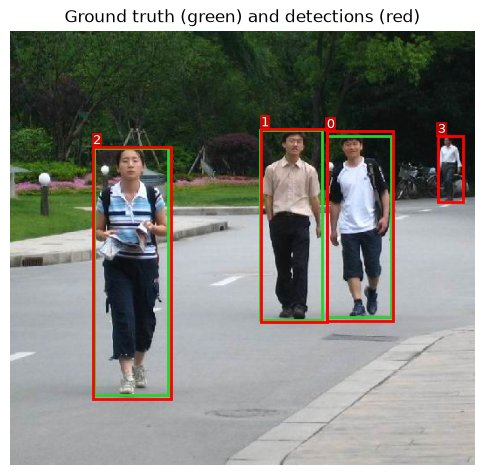

In [6]:
mask = pil_to_tensor(Image.open(image_dir / mask_name))[0]  # (height, width)
pedestrian_ids = mask.unique()[1:]  # without the background, 0
true_boxes = masks_to_boxes(mask == pedestrian_ids[:, None, None])

pedestrians = outputs[0]
is_person = pedestrians["labels"] == categories.index("person")
keep = (pedestrians["scores"] >= score_threshold) & is_person
person_boxes = pedestrians["boxes"][keep]
print(f"{len(true_boxes)} annotated pedestrians, {len(person_boxes)} detected persons")

fig, ax = plt.subplots(figsize=(6, 6))
show_image(ax, images[0])
draw_boxes(ax, true_boxes, color="limegreen")
draw_boxes(ax, person_boxes, [f"{i}" for i in range(len(person_boxes))])
ax.set_title("Ground truth (green) and detections (red)")
plt.show()

Let's compute the IoU by hand for two boxes: the intersection is the rectangle between the larger of the top left corners and the smaller of the bottom right corners (empty if these corners cross), and the union area is the sum of both areas minus the intersection's.

In [7]:
def iou(box_a, box_b):
  """IoU of two x1 y1 x2 y2 boxes."""
  x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
  x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
  intersection = max(0, x2 - x1) * max(0, y2 - y1)
  area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
  area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
  return intersection / (area_a + area_b - intersection)


truth = true_boxes[0].tolist()
for i, box in enumerate(person_boxes.tolist()):
  print(f"IoU(truth 0, detection {i}) = {iou(truth, box):.3f}")

IoU(truth 0, detection 0) = 0.000
IoU(truth 0, detection 1) = 0.000
IoU(truth 0, detection 2) = 0.933
IoU(truth 0, detection 3) = 0.000


torchvision's `box_iou` computes at once the matrix of IoUs between two sets of boxes: one row per detection, one column per ground truth box. Each detection is matched with the ground truth box it overlaps most, and considered correct if that IoU is above 0.5.

In [8]:
ious = box_iou(person_boxes, true_boxes)
print(ious.numpy().round(3))

best_ious, best_truths = ious.max(dim=1)
for i, (best_iou, truth) in enumerate(zip(best_ious, best_truths)):
  verdict = f"correct (truth {truth})" if best_iou > 0.5 else "wrong"
  print(f"Detection {i}: best IoU {best_iou:.3f} → {verdict}")

[[0.    0.    0.927]
 [0.    0.901 0.   ]
 [0.933 0.    0.   ]
 [0.    0.    0.   ]]
Detection 0: best IoU 0.927 → correct (truth 2)
Detection 1: best IoU 0.901 → correct (truth 1)
Detection 2: best IoU 0.933 → correct (truth 0)
Detection 3: best IoU 0.000 → wrong


The three annotated pedestrians are detected with an IoU close to 0.9. The man in the background is a person indeed, but the database didn't annotate him: the evaluation counts his detection as wrong. A metric like mAP is only as good as the annotation.

## Non-Maximum Suppression (NMS)

The detector often produces several boxes for the same object. Its ROI head applies a per-class NMS before returning its detections, with an IoU threshold of 0.5 (`model.roi_heads.nms_thresh`). To see the duplicate boxes, let's turn it off: with an IoU threshold of 1, no box is removed, since an IoU never exceeds 1. We also raise the limit of 100 detections per image (`detections_per_img`), then restore both settings.

In [9]:
settings = model.roi_heads.nms_thresh, model.roi_heads.detections_per_img
print(f"Model's NMS threshold: {settings[0]}")
model.roi_heads.nms_thresh, model.roi_heads.detections_per_img = 1.0, 1000
with torch.no_grad():
  raw = model([preprocess(images[0])])[0]
model.roi_heads.nms_thresh, model.roi_heads.detections_per_img = settings

keep = raw["scores"] >= score_threshold
raw_boxes, raw_scores, raw_labels = (
  raw["boxes"][keep],
  raw["scores"][keep],
  raw["labels"][keep],
)
print(f"Without NMS: {len(raw_boxes)} boxes with a score >= {score_threshold}")
print(Counter(categories[label] for label in raw_labels).most_common())

Model's NMS threshold: 0.5
Without NMS: 149 boxes with a score >= 0.5
[('person', 65), ('bicycle', 48), ('backpack', 33), ('sports ball', 3)]


Let's write NMS by hand, for one class, the persons:

1. keep the box with the highest score;
2. remove the boxes that overlap it too much (IoU > threshold);
3. repeat with the remaining boxes.

Then let's compare its result with that of torchvision's `nms`, which returns the indices of the kept boxes.

Persons: 65 boxes → 4 after NMS
Same boxes as torchvision: True


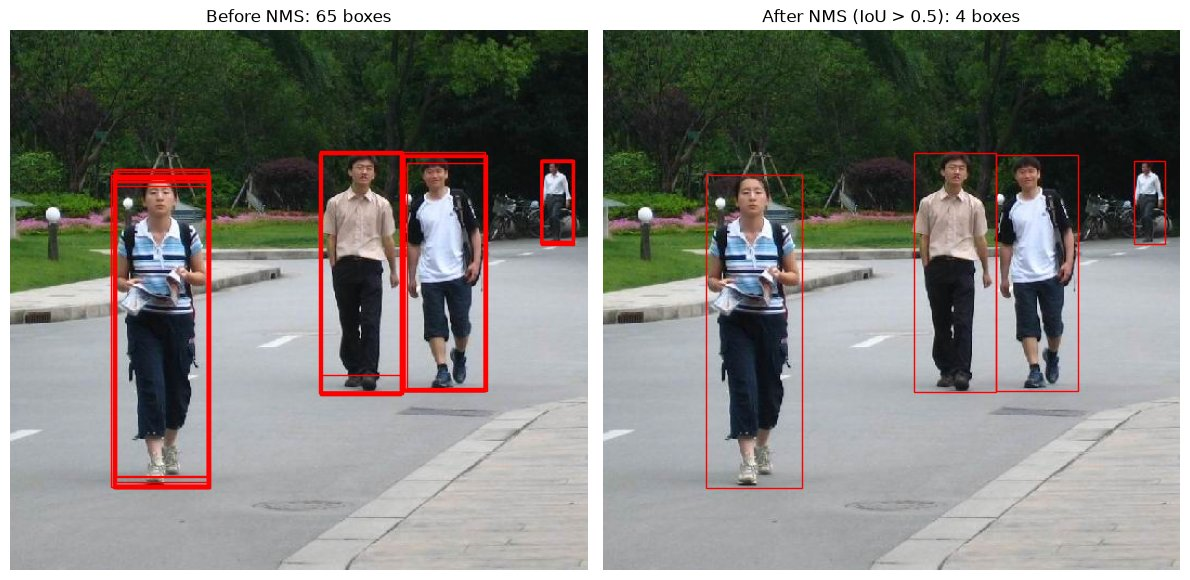

In [10]:
def nms_by_hand(boxes, scores, iou_threshold):
  """Indices of the kept boxes, by decreasing score."""
  remaining = scores.argsort(descending=True)
  kept = []
  while len(remaining) > 0:
    best, others = remaining[0], remaining[1:]
    kept.append(int(best))  # 1. the box with the highest score
    ious = box_iou(boxes[best].unsqueeze(0), boxes[others])[0]
    remaining = others[ious <= iou_threshold]  # 2. without those overlapping it
  return torch.tensor(kept)  # 3. until none is left


is_person = raw_labels == categories.index("person")
boxes, scores = raw_boxes[is_person], raw_scores[is_person]
kept_by_hand = nms_by_hand(boxes, scores, iou_threshold=0.5)
kept = nms(boxes, scores, iou_threshold=0.5)
print(f"Persons: {len(boxes)} boxes → {len(kept_by_hand)} after NMS")
print(f"Same boxes as torchvision: {torch.equal(kept_by_hand, kept)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, title, shown in (
  (axes[0], f"Before NMS: {len(boxes)} boxes", torch.arange(len(boxes))),
  (axes[1], f"After NMS (IoU > 0.5): {len(kept)} boxes", kept),
):
  show_image(ax, images[0])
  draw_boxes(ax, boxes[shown], linewidth=1)
  ax.set_title(title)
plt.tight_layout()
plt.show()

NMS works class by class: a person box must not remove the box of the backpack it overlaps. `batched_nms` applies `nms` separately to each class. On all the boxes, it finds the model's detections again. The IoU threshold sets the trade-off: low, it also merges close objects (a crowd); high, it leaves duplicates.

In [11]:
kept = batched_nms(raw_boxes, raw_scores, raw_labels, iou_threshold=0.5)
model_labels = pedestrians["labels"][pedestrians["scores"] >= score_threshold]
print(f"After NMS: {sorted(categories[label] for label in raw_labels[kept])}")
print(f"The model: {sorted(categories[label] for label in model_labels)}")

for iou_threshold in (0.1, 0.3, 0.5, 0.7, 0.9):
  kept = batched_nms(raw_boxes, raw_scores, raw_labels, iou_threshold)
  print(f"IoU threshold {iou_threshold}: {len(kept)} boxes kept")

After NMS: ['backpack', 'backpack', 'backpack', 'backpack', 'bicycle', 'bicycle', 'bicycle', 'person', 'person', 'person', 'person', 'sports ball']
The model: ['backpack', 'backpack', 'backpack', 'backpack', 'bicycle', 'bicycle', 'bicycle', 'person', 'person', 'person', 'person', 'sports ball']
IoU threshold 0.1: 9 boxes kept
IoU threshold 0.3: 9 boxes kept
IoU threshold 0.5: 12 boxes kept
IoU threshold 0.7: 16 boxes kept
IoU threshold 0.9: 46 boxes kept


## Going Further

- torchvision's one-stage detectors (`retinanet_resnet50_fpn_v2`, `fcos_resnet50_fpn`, `ssdlite320_mobilenet_v3_large`) have the same interface: replace the model and compare their boxes and their speed. Transformer-based detectors (DETR, RT-DETR) directly predict a set of objects, without NMS.
- `torchmetrics.detection.MeanAveragePrecision` computes the mAP from the detections and the ground truth.
- [torchvision's tutorial](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html) fine-tunes this same Faster R-CNN on the Penn-Fudan database.